# Modeling

**Goal:** train and compare models that predict the energy use of non-residential buildings in Seattle, starting from the features built in `02_feature_engineering.ipynb`.

## 0. Setup

Imports and load the dataset with the engineered features.

`buildings_feature_engineered.parquet` is the output of `02_feature_engineering.ipynb`.

To generate it, run `notebooks/01_eda.ipynb` then `notebooks/02_feature_engineering.ipynb` from top to bottom. The file is written to `data/processed/buildings_feature_engineered.parquet`.

In [19]:
from collections.abc import Callable
from functools import partial
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from catboost import CatBoostRegressor
from IPython.display import display
from pandas.io.formats.style import Styler
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import MissingIndicator, SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import make_scorer, mean_absolute_error
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    cross_val_predict,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

df = pd.read_parquet("../data/processed/buildings_feature_engineered.parquet")
print(f"Dataset: {df.shape[0]} rows x {df.shape[1]} columns")

Dataset: 1535 rows x 12 columns


## 1. Train/test split

The test set is set aside now and is only used once, for the final evaluation. Everything else (imputation, encoding, feature selection, hyperparameters) is fitted on the training set only, inside the cross-validation.

- **Split:** 80% train / 20% test, fixed `random_state` for reproducibility.
- **Target:** `SiteEnergyUse(kBtu)` is right-skewed, so it is modeled as `log10` (decision of notebook 1). `y` is kept in kBtu: the model will be wrapped in a `TransformedTargetRegressor` (`func=np.log10`), which fits on `log10(y)` and returns predictions in kBtu, so the metrics are computed in kBtu.
- **Stratification:** a continuous target cannot be stratified directly. The target is cut into 10 quantile bins (deciles; the bins are identical on `y` and on `log10(y)`, since the log is monotonic), and the split is stratified on these bins so that the training and test sets cover the whole range of consumption, including the few very large buildings. The bins are computed on the whole dataset, but they are only used to draw the split: they are not a feature and never reach the models.

The check below compares the `log10` target distributions of the two sets (the log is only computed for display).

In [20]:
TARGET = "SiteEnergyUse(kBtu)"
RANDOM_STATE = 42

X = df.drop(columns=TARGET)
y = df[TARGET]  # kBtu; the log10 transform is done by TransformedTargetRegressor

# Stratify on deciles of the target (the bins are the same on y and log10(y))
y_bins = pd.qcut(y, q=10, labels=False)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y_bins, random_state=RANDOM_STATE
)
print(f"Train: {len(X_train)} rows | Test: {len(X_test)} rows")

Train: 1228 rows | Test: 307 rows


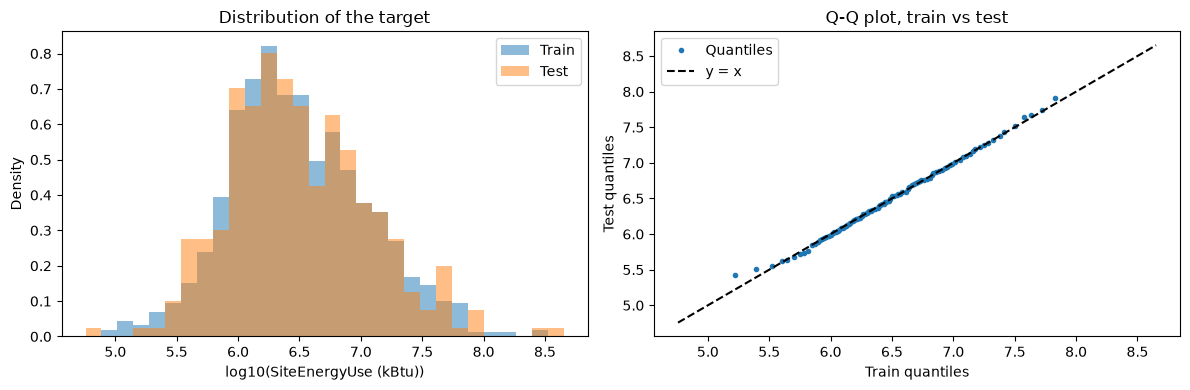

,Train,Test
count,1228.000,307.000
mean,6.492,6.498
std,0.564,0.577
min,4.902,4.757
25%,6.101,6.087
50%,6.437,6.429
75%,6.861,6.872
max,8.467,8.652


In [21]:
# Check: log10(y) distributions of the two sets (for display only)
log_train, log_test = np.log10(y_train), np.log10(y_test)
log_all = np.log10(y)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

bins = np.linspace(log_all.min(), log_all.max(), 31)
axes[0].hist(log_train, bins=bins, density=True, alpha=0.5, label="Train")
axes[0].hist(log_test, bins=bins, density=True, alpha=0.5, label="Test")
axes[0].set_xlabel("log10(SiteEnergyUse (kBtu))")
axes[0].set_ylabel("Density")
axes[0].set_title("Distribution of the target")
axes[0].legend()

quantiles = np.linspace(0.01, 0.99, 99)
axes[1].plot(
    log_train.quantile(quantiles), log_test.quantile(quantiles), ".", label="Quantiles"
)
axes[1].plot(
    [log_all.min(), log_all.max()], [log_all.min(), log_all.max()], "k--", label="y = x"
)
axes[1].set_xlabel("Train quantiles")
axes[1].set_ylabel("Test quantiles")
axes[1].set_title("Q-Q plot, train vs test")
axes[1].legend()

plt.tight_layout()
plt.show()

summary = pd.DataFrame({"Train": log_train.describe(), "Test": log_test.describe()})
display(summary.round(3))

In [22]:
counts = (
    pd.DataFrame(
        {
            "Train": X_train["PrimaryPropertyType"].value_counts(),
            "Test": X_test["PrimaryPropertyType"].value_counts(),
        }
    )
    .fillna(0)
    .astype(int)
)
counts["Test share"] = (counts["Test"] / (counts["Train"] + counts["Test"])).round(3)
counts.sort_values("Train", ascending=False)

,Train,Test,Test share
PrimaryPropertyType,,,
Small- and Mid-Sized Office,226,60,0.210
Other,197,48,0.196
Warehouse,147,38,0.205
Large Office,131,38,0.225
Mixed Use Property,80,24,0.231
Retail Store,73,12,0.141
Hotel,57,18,0.240
Worship Facility,56,13,0.188
Distribution Center,49,4,0.075


### Checks

- The stratification works. The two sets have almost the same mean (6.49 vs 6.50 in log10), median (6.44 vs 6.43) and spread, and the points of the Q-Q plot follow the diagonal over the whole range, including the largest consumers.
- The target is strictly positive (minimum of 4.76 in log10), so the log10 transform is always defined. The largest building of the test set (8.65) is above the maximum of the training set (8.47): the models will have to predict beyond the values they were trained on.
- Most property types have about 20% of their buildings in the test set. By chance, no hospital ends up in the test set. The split is kept as is: changing the random seed to fix this would mean choosing the test set after looking at it. The behavior of the models on hospitals is assessed through cross-validation instead, where each building is used once for validation.

## 2. Checks on the training set

Everything in this section uses `X_train` and `y_train` only. The exploration of notebooks 1 and 2 is not repeated: this section keeps the checks that drive the preprocessing choices (correlations with the target, property type, redundancy among the size variables). The signals of the engineered features (`ParkingShare`, `FloorAreaPerFloor`) hold on the training set, as in notebook 2.

As in notebook 2, the **intensity** (energy use divided by the building area) is used next to the target itself, because the building area dominates the total energy use and hides the other signals.

### Correlations with the target

Spearman rank correlations (insensitive to the skew, no need to log-transform).

In [23]:
train = X_train.assign(
    log_y=np.log10(y_train),
    log_intensity=np.log10(y_train / X_train["PropertyGFABuilding(s)"]),
)

numeric = [
    "PropertyGFABuilding(s)",
    "NumberofFloors",
    "NumberofBuildings",
    "FloorAreaPerFloor",
    "ParkingShare",
    "HasMixedUsage",
    "Latitude",
    "Longitude",
]
corr = pd.DataFrame(
    {
        "vs log10(y)": train[numeric].corrwith(train["log_y"], method="spearman"),
        "vs log10(intensity)": train[numeric].corrwith(
            train["log_intensity"], method="spearman"
        ),
    }
)
corr.round(2)

,vs log10(y),vs log10(intensity)
PropertyGFABuilding(s),0.71,0.11
NumberofFloors,0.47,0.16
NumberofBuildings,0.12,0.09
FloorAreaPerFloor,0.23,-0.08
ParkingShare,0.31,0.21
HasMixedUsage,0.10,0.04
Latitude,0.06,0.12
Longitude,-0.04,-0.02


The total energy use is mostly driven by the building area (Spearman 0.71 with `log10(y)`), which hides everything else. Against the intensity (energy use per unit of area), the picture changes:

- `ParkingShare` is the strongest of the engineered features (0.21 with the intensity, 0.31 with `log10(y)`, because parking is correlated with large buildings).
- `FloorAreaPerFloor` is weak and changes sign: +0.23 with `log10(y)` (wider buildings are larger) but -0.08 with the intensity.
- `HasMixedUsage` (0.04), `NumberofBuildings` (0.09) and `Longitude` (-0.02) are weak. `NumberofFloors` (0.16) and `Latitude` (0.12) are modest.
- A rank correlation only sees monotonic relationships. The construction period and the property type are categorical and not in this table; their relationships were studied in notebooks 1 and 2.

These are descriptive values on the training set. The real test of a feature is its contribution to the model, assessed later with cross-validation.

The property type is categorical, so it is not in this table: its relationship with the intensity is shown below.

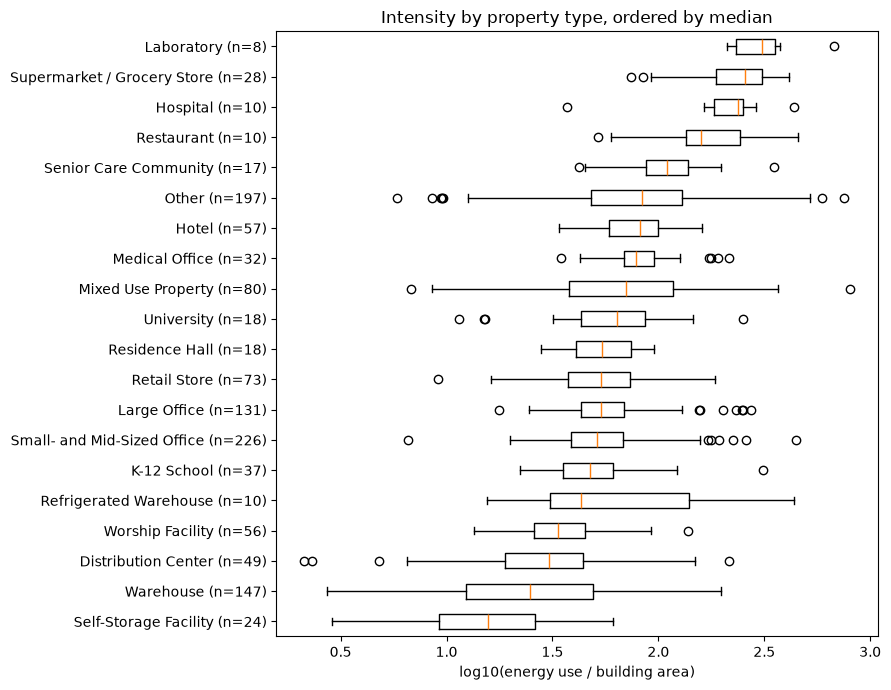

In [24]:
order = (
    train.groupby("PrimaryPropertyType")["log_intensity"].median().sort_values().index
)
groups = [train.loc[train["PrimaryPropertyType"] == t, "log_intensity"] for t in order]

fig, ax = plt.subplots(figsize=(9, 7))
ax.boxplot(
    groups,
    tick_labels=[f"{t} (n={len(g)})" for t, g in zip(order, groups)],
    orientation="horizontal",
)
ax.set_xlabel("log10(energy use / building area)")
ax.set_title("Intensity by property type, ordered by median")
plt.tight_layout()
plt.show()

The property type is the strongest driver of the energy use per unit of area. The median intensity ranges from about 1.2 (Self-Storage Facility) to about 2.5 (Laboratory) in log10: a laboratory uses about 20 times more energy per square foot than a self-storage facility. The order matches the business intuition: laboratories, supermarkets (refrigeration), hospitals (24/7 operation) and restaurants (cooking) are at the top, storage buildings at the bottom.

The spread inside each type varies a lot:
- Offices, the most frequent types (226 and 131 buildings), have narrow boxes: their intensity is homogeneous, so they should be well predicted.
- The catch-all categories (Other, Mixed Use Property) and Warehouse have wide boxes: they group buildings with very different actual uses. Other is the second most frequent type (197 buildings), so most prediction errors are expected there.
- The rarest types (8 to 10 buildings) are among the most extreme. Grouping rare categories at encoding time (`min_frequency`, `max_categories`) would merge laboratories, hospitals and refrigerated warehouses into a single column and lose the strongest signal of the dataset: all property types are therefore kept as separate categories.

### Redundancy among the size variables

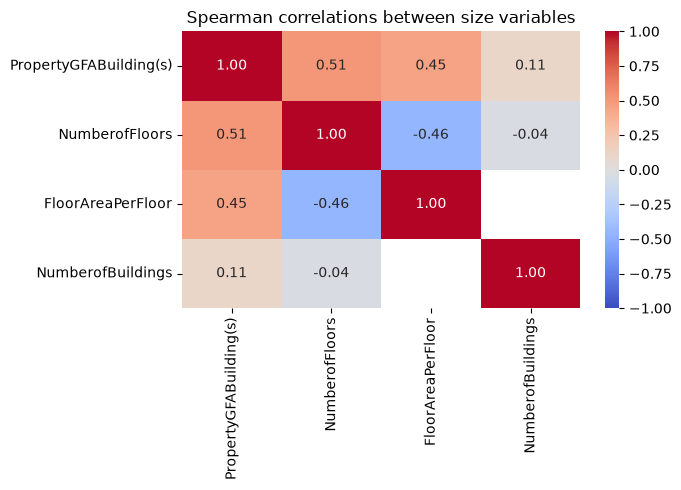

In [25]:
size_cols = [
    "PropertyGFABuilding(s)",
    "NumberofFloors",
    "FloorAreaPerFloor",
    "NumberofBuildings",
]

fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(
    train[size_cols].corr(method="spearman"),
    annot=True,
    fmt=".2f",
    vmin=-1,
    vmax=1,
    cmap="coolwarm",
    ax=ax,
)
ax.set_title("Spearman correlations between size variables")
plt.tight_layout()
plt.show()

- The size variables are moderately correlated (0.45 to 0.51), and `NumberofBuildings` is almost independent of them.
- By construction, area = floors × area per floor: any one of the three can be computed exactly from the other two. The linear model therefore gets only two of them. Tree-based models can keep all three, but their importance will have to be read together.
- `FloorAreaPerFloor` is missing for all campuses (hence the empty cell in the heatmap), so its missing values carry information: an indicator column will be added at imputation.

## 3. Preprocessing

Three preprocessors, one per model. All are `ColumnTransformer`s that will be the first step of a pipeline, so that imputation, scaling and encoding are fitted on the training folds only.

| | Linear models | Random forest | CatBoost |
|---|---|---|---|
| Skewed sizes (`PropertyGFABuilding(s)`, `NumberofFloors`, `NumberofBuildings`) | `log10` | as is (trees only use the order of the values) | as is |
| Size variables | area + floors; `FloorAreaPerFloor` is dropped (area = floors × area per floor, a linear model cannot take all three) | all three | all three |
| Missing values (`FloorAreaPerFloor`, `NumberofFloors`) | median + missing indicator | median + missing indicator | median + missing indicator | 
| Scaling | `StandardScaler` on the numeric variables (needed for regularisation); binary variables and missing indicators are never scaled, to stay readable | none | none |
| Categories (`PrimaryPropertyType`, `Neighborhood`, `ConstructionPeriod`) | one-hot, unknown category ignored | one-hot, unknown category ignored | as is (CatBoost handles categories natively) |
| `ParkingShare`, `Latitude`, `Longitude` | scaled | as is | as is |
| `HasMixedUsage` (binary) | as is | as is | as is |

- The missing `FloorAreaPerFloor` values are mostly campuses (see section 2). The tree models keep the missing indicator for them. The linear model does not use this feature, so `NumberofBuildings` is its only campus signal. An indicator only exists for columns with missing values in the training data.
- No `min_frequency` in the one-hot encoding: the rare property types are the most extreme ones and must keep their own column.
- Which of the three size variables to drop for the linear model is a modeling choice: `FloorAreaPerFloor` is dropped because it has fewer imputed values (11 instead of 51), and floor area has no physical meaning for a campus.

In [26]:
X_train.isna().sum()

PropertyGFABuilding(s)     0
PrimaryPropertyType        0
NumberofFloors            11
NumberofBuildings          0
Neighborhood               0
Latitude                   0
Longitude                  0
ParkingShare               0
HasMixedUsage              0
ConstructionPeriod         0
FloorAreaPerFloor         51
dtype: int64

In [27]:
CATEGORICAL = ["PrimaryPropertyType", "Neighborhood", "ConstructionPeriod"]
LOG_COLS = ["PropertyGFABuilding(s)", "NumberofFloors", "NumberofBuildings"]
PLAIN_NUMERIC_COLS = [
    "ParkingShare",
    "Latitude",
    "Longitude",
]  # no log; scaled for the linear models only
BINARY_COLS = ["HasMixedUsage"]  # already 0/1, never scaled
TREE_ONLY_COLS = [
    "FloorAreaPerFloor"
]  # redundant with the two size variables for a linear model


def make_one_hot():
    return OneHotEncoder(handle_unknown="ignore", sparse_output=False)


def make_imputer(add_indicator):
    return SimpleImputer(strategy="median", add_indicator=add_indicator)


def make_linear_preprocessor():
    """Log of the skewed sizes, scaling, imputation, one-hot encoding.

    The missing indicator is generated by its own step, outside of the sub-pipeline,
    so that it is not scaled.
    """
    log_pipeline = make_pipeline(
        FunctionTransformer(np.log10, feature_names_out="one-to-one"),
        StandardScaler(),
        make_imputer(add_indicator=False),
    )
    return ColumnTransformer(
        [
            ("log", log_pipeline, LOG_COLS),
            ("missing", MissingIndicator(features="missing-only"), ["NumberofFloors"]),
            ("plain_numeric", StandardScaler(), PLAIN_NUMERIC_COLS),
            ("binary", "passthrough", BINARY_COLS),
            ("cat", make_one_hot(), CATEGORICAL),
        ],
        remainder="drop",  # FloorAreaPerFloor
        verbose_feature_names_out=False,
    ).set_output(transform="pandas")


def make_tree_preprocessor():
    """No transformation of the values: imputation (with indicator) and one-hot encoding."""
    return ColumnTransformer(
        [
            ("num", make_imputer(add_indicator=True), LOG_COLS + TREE_ONLY_COLS),
            ("plain", "passthrough", PLAIN_NUMERIC_COLS + BINARY_COLS),
            ("cat", make_one_hot(), CATEGORICAL),
        ],
        verbose_feature_names_out=False,
    ).set_output(transform="pandas")


def make_catboost_preprocessor():
    """No transformation of the values: imputation (with indicator).

    Categories are encoded by CatBoost itself (ordered target statistics) via cat_features.
    """
    return ColumnTransformer(
        [
            ("num", make_imputer(add_indicator=True), LOG_COLS + TREE_ONLY_COLS),
            ("plain", "passthrough", PLAIN_NUMERIC_COLS + BINARY_COLS),
            ("cat", "passthrough", CATEGORICAL),
        ],
        verbose_feature_names_out=False,
    ).set_output(transform="pandas")

### Check

Each preprocessor is fitted on the training set and applied to both sets (only to check the output: during the modeling, the fit happens inside the cross-validation). The output must have no missing value, and the linear one must have centered numeric columns.

In [28]:
for name, make in [
    ("Linear", make_linear_preprocessor),
    ("Trees", make_tree_preprocessor),
    ("CatBoost", make_catboost_preprocessor),
]:
    prep = make().fit(X_train)
    out_train, out_test = prep.transform(X_train), prep.transform(X_test)
    assert not out_train.isna().any().any() and not out_test.isna().any().any()
    print(f"{name}: {X_train.shape[1]} -> {out_train.shape[1]} columns")
    indicators = [c for c in out_train.columns if c.startswith("missingindicator")]
    print(f"  missing indicators: {indicators}")

linear_out = make_linear_preprocessor().fit_transform(X_train)
linear_out.iloc[:, :6].astype(float).describe().loc[
    ["mean", "std", "min", "max"]
].round(2)

Linear: 11 -> 46 columns
  missing indicators: ['missingindicator_NumberofFloors']
Trees: 11 -> 48 columns
  missing indicators: ['missingindicator_NumberofFloors', 'missingindicator_FloorAreaPerFloor']
CatBoost: 11 -> 13 columns
  missing indicators: ['missingindicator_NumberofFloors', 'missingindicator_FloorAreaPerFloor']


,PropertyGFABuilding(s),NumberofFloors,NumberofBuildings,missingindicator_NumberofFloors,ParkingShare,Latitude
mean,0.00,-0.00,-0.00,0.01,0.00,0.00
std,1.00,1.00,1.00,0.09,1.00,1.00
min,-1.82,-1.14,-0.17,0.00,-0.45,-2.26
max,3.77,3.90,11.81,1.00,5.10,2.48


## 4. Evaluation protocol

| Element | Choice |
|---|---|
| Cross-validation | 5 folds, stratified on the deciles of `y_train`, built once and shared by all the models |
| Decision metric | MAE on `log10` (`log10_mae`), with the same weight for small and large buildings. It ranks the models, but its value is hard to read on its own |
| Readable metrics | Share of buildings predicted within ±25% and within ±50% of their actual energy use, and the median relative error (half of the buildings have a smaller error) |
| Metrics in kBtu | R², MAE and RMSE, dominated by the largest buildings, and the total bias: total predicted energy use vs total actual energy use |
| Baselines | A `DummyRegressor` (sanity floor) and a business rule, building area × median intensity of the property type: **the reference to beat** |
| Overfitting signal | Gap between the mean train and validation scores (positive when the model does worse on validation) |

All the models learn `log10(y)` through a `TransformedTargetRegressor` and predict in kBtu.

`evaluate_model` cross-validates a model and returns one row of the results table. Scorer keys starting with `neg_` are errors: scikit-learn negates them, so the sign is flipped back and the prefix removed. Two display functions show the results: the decision table (log10 MAE and readable metrics) and the metrics in kBtu.

In [29]:
def evaluate_model(
    model: Any,
    X: pd.DataFrame,
    y: pd.Series,
    cv: list[tuple[np.ndarray, np.ndarray]],
    scorers: dict[str, str | Callable],
    model_name: str,
) -> dict[str, Any]:
    """Cross-validate a model on explicit folds and return one row of the summary table.

    Train and validation scores are averaged over the folds (mean and std). Keys starting
    with 'neg_' are errors: the sign is flipped back and the prefix removed. The gap is
    positive when the model does worse on validation (val - train for errors, train - val otherwise).
    """
    results = cross_validate(
        model,
        X,
        y,
        cv=cv,
        scoring=scorers,
        return_train_score=True,
    )

    row: dict[str, Any] = {
        "model": model_name,
        "fit_time_mean": results["fit_time"].mean(),
    }
    for key in scorers:
        is_error = key.startswith("neg_")
        name = key.removeprefix("neg_")
        sign = -1 if is_error else 1  # scikit-learn negates errors: flip them back

        train = sign * results[f"train_{key}"]
        val = sign * results[f"test_{key}"]

        row[f"{name}_train_mean"] = train.mean()
        row[f"{name}_train_std"] = train.std()
        row[f"{name}_val_mean"] = val.mean()
        row[f"{name}_val_std"] = val.std()
        row[f"{name}_gap"] = (
            val.mean() - train.mean() if is_error else train.mean() - val.mean()
        )
    return row


def with_log_target(regressor: Any) -> TransformedTargetRegressor:
    """Wrap a regressor so that it learns log10(y) and predicts in kBtu."""
    return TransformedTargetRegressor(
        regressor=regressor, func=np.log10, inverse_func=partial(np.power, 10.0)
    )


def decision_table(results: pd.DataFrame) -> Styler:
    """Validation scores used to compare the models; the best log10 MAE is in bold."""
    table = pd.DataFrame(
        {
            "log10 MAE": results["log10_mae_val_mean"],
            "std": results["log10_mae_val_std"],
            "gap": results["log10_mae_gap"],
            "within ±25%": results["within_25_val_mean"],
            "within ±50%": results["within_50_val_mean"],
            "median error": results["median_ape_val_mean"],
            "fit time (s)": results["fit_time_mean"],
        }
    )
    return (
        table.style.format("{:.3f}", subset=["log10 MAE", "std", "gap"])
        .format("{:.0%}", subset=["within ±25%", "within ±50%", "median error"])
        .format("{:.2f}", subset=["fit time (s)"])
        .highlight_min(subset=["log10 MAE"], props="font-weight: bold")
    )


def kbtu_table(results: pd.DataFrame) -> Styler:
    """Validation R2, MAE, RMSE in kBtu and total bias, one row per model."""
    table = pd.DataFrame(
        {
            "R2": results["r2_val_mean"],
            "MAE (kBtu)": results["mean_absolute_error_val_mean"],
            "RMSE (kBtu)": results["root_mean_squared_error_val_mean"],
            "total bias": results["total_bias_val_mean"],
        }
    )
    return table.style.format(
        {
            "R2": "{:.3f}",
            "MAE (kBtu)": "{:,.0f}",
            "RMSE (kBtu)": "{:,.0f}",
            "total bias": "{:+.1%}",
        }
    )

### Folds and scorers

The folds are recomputed on the deciles of `y_train` (not the `y_bins` of the train/test split). The list of positional indices is passed as is to `evaluate_model`.

In [30]:
y_train_bins = pd.qcut(y_train, q=10, labels=False)

cv = list(
    StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE).split(
        X_train, y_train_bins
    )
)

for i, (train_idx, val_idx) in enumerate(cv, start=1):
    print(f"Fold {i}: train {len(train_idx)} rows | validation {len(val_idx)} rows")
assert sorted(np.concatenate([val for _, val in cv])) == list(range(len(X_train)))

Fold 1: train 982 rows | validation 246 rows
Fold 2: train 982 rows | validation 246 rows
Fold 3: train 982 rows | validation 246 rows
Fold 4: train 983 rows | validation 245 rows
Fold 5: train 983 rows | validation 245 rows


In [31]:
def log10_mae(y_true, y_pred):
    return mean_absolute_error(np.log10(y_true), np.log10(y_pred))


def share_within(y_true, y_pred, tol):
    """Share of buildings predicted within ±tol of their actual energy use (0.25 = ±25%)."""
    return np.mean(np.abs(y_pred - y_true) / y_true <= tol)


def median_ape(y_true, y_pred):
    """Median relative error: half of the buildings have a smaller error."""
    return np.median(np.abs(y_pred - y_true) / y_true)


def total_bias(y_true, y_pred):
    """Relative gap between the total predicted and the total actual energy use."""
    return y_pred.sum() / y_true.sum() - 1


scorers = {
    "r2": "r2",
    "neg_mean_absolute_error": "neg_mean_absolute_error",
    "neg_root_mean_squared_error": "neg_root_mean_squared_error",
    "neg_log10_mae": make_scorer(log10_mae, greater_is_better=False),
    "within_25": make_scorer(share_within, tol=0.25),
    "within_50": make_scorer(share_within, tol=0.5),
    "neg_median_ape": make_scorer(median_ape, greater_is_better=False),
    "total_bias": make_scorer(total_bias),
}

### Baselines

Two references, evaluated on the same folds as the models:

- **Dummy model**: a `DummyRegressor` that predicts the mean of `log10(y)` for every building (the geometric mean in kBtu), wrapped with `with_log_target` like the other models. It learns nothing from the features: it is a sanity floor that every model must beat by far. Its R² is slightly negative by construction: R² compares the predictions with the average consumption (about 8.0 million kBtu), while the dummy predicts a typical building (about 3.1 million kBtu).
- **Business rule**: building area × median energy use per sq ft of the property type, learned on the training folds. It is what the city could compute without machine learning, from the two strongest signals of the exploration (area and type). **It is the reference to beat**: a model is only worth it if it does better than this rule.

In [32]:
class TypeIntensityBaseline(RegressorMixin, BaseEstimator):
    """Business rule: building area x median intensity of the property type, in kBtu.

    The median log10 intensity of each type is learned on the training data; a type
    unseen during fit gets the overall median.
    """

    def fit(self, X, y):
        log_intensity = np.log10(y / X["PropertyGFABuilding(s)"])
        self.medians_ = log_intensity.groupby(X["PrimaryPropertyType"]).median()
        self.global_median_ = log_intensity.median()
        return self

    def predict(self, X):
        log_intensity = (
            X["PrimaryPropertyType"]
            .map(self.medians_)
            .astype(float)
            .fillna(self.global_median_)
        )
        return (10**log_intensity * X["PropertyGFABuilding(s)"]).to_numpy()


baselines = {
    "Dummy (mean of log10)": with_log_target(DummyRegressor(strategy="mean")),
    "Business rule (area x type)": TypeIntensityBaseline(),
}
baseline_rows = [
    evaluate_model(model, X_train, y_train, cv, scorers, name)
    for name, model in baselines.items()
]
baseline_results = pd.DataFrame(baseline_rows).set_index("model")
display(decision_table(baseline_results))
display(kbtu_table(baseline_results))

,log10 MAE,std,gap,within ±25%,within ±50%,median error,fit time (s)
model,,,,,,,
Dummy (mean of log10),0.451,0.004,-0.000,14%,29%,78%,0.01
Business rule (area x type),0.221,0.010,0.006,37%,63%,37%,0.00


,R2,MAE (kBtu),RMSE (kBtu),total bias
model,,,,
Dummy (mean of log10),-0.073,"6,657,011","19,144,851",-60.7%
Business rule (area x type),0.769,"3,090,725","8,263,563",-10.9%


## 5. Model comparison

Three models from three families, with their default settings, on the same folds:

- **Ridge** (linear model with L2 regularisation, `alpha=1`) on the linear preprocessor;
- **Random forest** (bagging of deep trees: 100 trees, no depth limit) on the tree preprocessor;
- **CatBoost** (boosting of symmetric trees: 1000 iterations of depth 6) on its own preprocessor, with native categorical features. `verbose=0` and `allow_writing_files=False` only silence the training log and the `catboost_info/` folder.

The hyperparameters are tuned in section 6.

In [33]:
models = {
    "Ridge (alpha=1)": with_log_target(
        make_pipeline(make_linear_preprocessor(), Ridge())
    ),
    "Random forest (default)": with_log_target(
        make_pipeline(
            make_tree_preprocessor(), RandomForestRegressor(random_state=RANDOM_STATE)
        )
    ),
    "CatBoost (default)": with_log_target(
        make_pipeline(
            make_catboost_preprocessor(),
            CatBoostRegressor(
                random_state=RANDOM_STATE,
                verbose=0,
                allow_writing_files=False,
                cat_features=tuple(CATEGORICAL),
            ),
        )
    ),
}

rows = baseline_rows + [
    evaluate_model(model, X_train, y_train, cv, scorers, name)
    for name, model in models.items()
]
results = pd.DataFrame(rows).set_index("model")
decision_table(results)

,log10 MAE,std,gap,within ±25%,within ±50%,median error,fit time (s)
model,,,,,,,
Dummy (mean of log10),0.451,0.004,-0.000,14%,29%,78%,0.01
Business rule (area x type),0.221,0.010,0.006,37%,63%,37%,0.00
Ridge (alpha=1),0.218,0.008,0.009,35%,64%,37%,0.04
Random forest (default),0.235,0.004,0.148,33%,62%,39%,0.72
CatBoost (default),0.223,0.005,0.082,34%,64%,38%,2.01


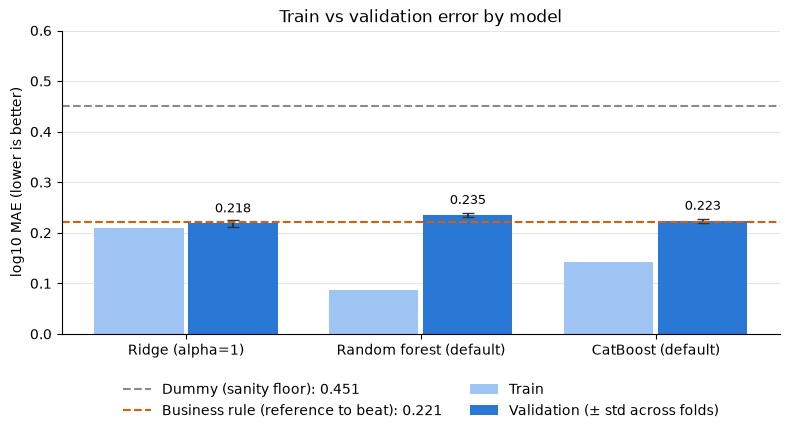

In [34]:
# Same data as the decision table: train vs validation log10 MAE, baselines as reference lines
compared = results.drop(index=list(baselines))
x = np.arange(len(compared))
width = 0.38

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(
    x - width / 2 - 0.01,
    compared["log10_mae_train_mean"],
    width,
    color="#9ec5f4",
    label="Train",
)
ax.bar(
    x + width / 2 + 0.01,
    compared["log10_mae_val_mean"],
    width,
    yerr=compared["log10_mae_val_std"],
    capsize=4,
    color="#2a78d6",
    ecolor="#333333",
    label="Validation (± std across folds)",
)
for xi, value in zip(x, compared["log10_mae_val_mean"]):
    ax.annotate(
        f"{value:.3f}",
        (xi + width / 2 + 0.01, value),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center",
        fontsize=9,
    )

references = {
    "Dummy (mean of log10)": ("Dummy (sanity floor)", "#8a8a8a"),
    "Business rule (area x type)": ("Business rule (reference to beat)", "#d95f02"),
}
for name, (label, color) in references.items():
    value = results.loc[name, "log10_mae_val_mean"]
    ax.axhline(
        value, color=color, linestyle="--", linewidth=1.5, label=f"{label}: {value:.3f}"
    )

ax.set_xticks(x, compared.index)
ax.set_ylim(0, 0.6)
ax.set_ylabel("log10 MAE (lower is better)")
ax.set_title("Train vs validation error by model")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e5e5e5")
ax.set_axisbelow(True)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)
plt.tight_layout()
plt.show()

In [35]:
kbtu_table(results)

,R2,MAE (kBtu),RMSE (kBtu),total bias
model,,,,
Dummy (mean of log10),-0.073,"6,657,011","19,144,851",-60.7%
Business rule (area x type),0.769,"3,090,725","8,263,563",-10.9%
Ridge (alpha=1),0.723,"3,304,013","9,233,231",-11.4%
Random forest (default),0.725,"3,416,659","9,346,998",-19.0%
CatBoost (default),0.723,"3,391,345","9,566,857",-17.4%


### Share of buildings within a given error

The same comparison, read differently: for each tolerance (±10%, ±20%, ...), the share of training buildings whose prediction falls within that tolerance of their actual energy use. The higher the curve, the better the model. The predictions are out-of-fold: each building is predicted by a model fitted without its fold, on the same folds as above.

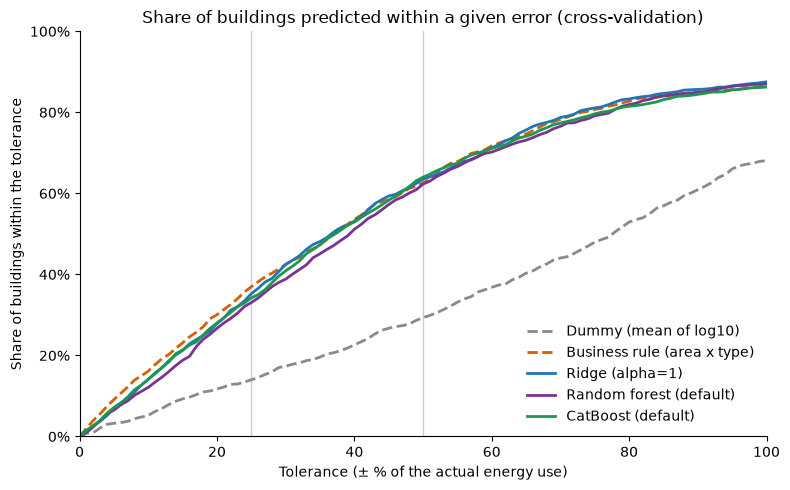

In [36]:
tolerances = np.linspace(0, 1, 101)
styles = {
    "Dummy (mean of log10)": {"color": "#8a8a8a", "linestyle": "--"},
    "Business rule (area x type)": {"color": "#d95f02", "linestyle": "--"},
    "Ridge (alpha=1)": {"color": "#1f77b4"},
    "Random forest (default)": {"color": "#7b3294"},
    "CatBoost (default)": {"color": "#1a9850"},
}

fig, ax = plt.subplots(figsize=(8, 5))
for name, model in {**baselines, **models}.items():
    y_pred = cross_val_predict(model, X_train, y_train, cv=cv)
    relative_error = np.abs(y_pred - y_train) / y_train
    share = [(relative_error <= t).mean() for t in tolerances]
    ax.plot(tolerances * 100, share, label=name, linewidth=2, **styles.get(name, {}))

for t in (25, 50):
    ax.axvline(t, color="#cccccc", linewidth=1, zorder=0)
ax.set_xlabel("Tolerance (± % of the actual energy use)")
ax.set_ylabel("Share of buildings within the tolerance")
ax.yaxis.set_major_formatter("{x:.0%}")
ax.set_xlim(0, 100)
ax.set_ylim(0, 1)
ax.set_title("Share of buildings predicted within a given error (cross-validation)")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

### Reading the comparison

- **All three models beat the dummy by far, but none of them clearly beats the business rule.** Ridge has a slightly lower log10 MAE (0.218 vs 0.221), while the rule places slightly more buildings within ±25% (37% vs 35%). These differences are smaller than the spread across folds (std 0.008 to 0.010): with their default settings, the models predict about as well as area × median intensity of the type.
- **What this means for the city.** About one building in three is estimated within ±25% of its actual energy use, and about two in three within ±50%. For half of the buildings, the error is below about 37%. Every approach reaches this level, simple or not.
- **Why the models do not go further.** Area and type are the two strongest signals (notebook 1), and the rule already uses them in the most direct way. The other features (location, construction period, parking share, mixed usage, floor area per floor) add little, and three very different model families stop at the same level. The remaining error mostly comes from what the data does not contain (occupancy, equipment, operating hours).
- **The tree-based models overfit with their default settings**: a gap of 0.08 to 0.15, against 0.009 for Ridge. The hyperparameter search of section 6 has to show whether a tuned model can beat the rule. If none does, that is a valid conclusion in itself.
- **In kBtu**, the rule even has the best R² (0.77, against about 0.72 for the models).
- **All the approaches underestimate the total energy use**: −11% for the rule and Ridge, −17% to −19% for the tree-based models. A model trained on `log10(y)` predicts a typical value rather than an average one, which falls below the actual value of the largest consumers. This does not matter to estimate one building, but it does if the city adds up the predictions to estimate its whole building stock.

## 6. Hyperparameter optimization

Grid search on CatBoost, on the same folds and with the same scorers as the comparison. The model is selected on the decision metric (`log10_mae`), and the other scorers are kept to read the result.

CatBoost is the model with the most reducible overfitting gap (0.08 with the default settings), and it handles the categories natively. Ridge has only one hyperparameter (`alpha`) and almost no gap to reduce, so there is little to gain from tuning it. The random forest has the largest gap, but CatBoost is the better of the two tree-based models.

The ranges enclose the default values of `learning_rate` and `l2_leaf_reg`. `depth` only goes down from its default (6), to test whether shallower trees overfit less. `l2_leaf_reg` is on a logarithmic scale (1, 3, 10, 30), because its effect is multiplicative. The grid covers both smaller and larger products of `learning_rate` × `iterations` than the defaults (from 18 to 150, against about 40): the total amount of learning can go down or up.

**Success criterion.** The tuned model must beat the business rule (log10 MAE of 0.221) by more than the difference between folds (std of 0.006 to 0.010).

| Hyperparameter | Values |
|---|---|
| `depth` | 4, 5, 6 |
| `l2_leaf_reg` | 1, 3, 10, 30 |
| `learning_rate` | 0.03, 0.05, 0.1 |
| `iterations` | 600, 1000, 1500 |

This is 3 × 4 × 3 × 3 = 108 combinations, each cross-validated on 5 folds (540 fits). The parameters are prefixed by the step names of the pipeline: `regressor__` for the model inside `TransformedTargetRegressor`, then `catboostregressor__`.

In [38]:
catboost_model = with_log_target(
    make_pipeline(
        make_catboost_preprocessor(),
        CatBoostRegressor(
            random_state=RANDOM_STATE,
            verbose=0,
            allow_writing_files=False,
            cat_features=tuple(CATEGORICAL),
        ),
    )
)

param_grid = {
    "regressor__catboostregressor__depth": [4, 5, 6],
    "regressor__catboostregressor__l2_leaf_reg": [1, 3, 10, 30],
    "regressor__catboostregressor__learning_rate": [0.03, 0.05, 0.1],
    "regressor__catboostregressor__iterations": [600, 1000, 1500],
}

grid = GridSearchCV(
    catboost_model,
    param_grid,
    cv=cv,
    scoring=scorers,
    refit="neg_log10_mae",
    return_train_score=True,
    verbose=2,
)
grid.fit(X_train, y_train)

best_params = {k.split("__")[-1]: v for k, v in grid.best_params_.items()}
print(f"Best parameters: {best_params}")
print(f"Best validation log10 MAE: {-grid.best_score_:.3f}")

Fitting 5 folds for each of 108 candidates, totalling 540 fits
[CV] END regressor__catboostregressor__depth=4, regressor__catboostregressor__iterations=600, regressor__catboostregressor__l2_leaf_reg=1, regressor__catboostregressor__learning_rate=0.03; total time=   0.5s
[CV] END regressor__catboostregressor__depth=4, regressor__catboostregressor__iterations=600, regressor__catboostregressor__l2_leaf_reg=1, regressor__catboostregressor__learning_rate=0.03; total time=   0.4s
[CV] END regressor__catboostregressor__depth=4, regressor__catboostregressor__iterations=600, regressor__catboostregressor__l2_leaf_reg=1, regressor__catboostregressor__learning_rate=0.03; total time=   0.4s
[CV] END regressor__catboostregressor__depth=4, regressor__catboostregressor__iterations=600, regressor__catboostregressor__l2_leaf_reg=1, regressor__catboostregressor__learning_rate=0.03; total time=   0.4s
[CV] END regressor__catboostregressor__depth=4, regressor__catboostregressor__iterations=600, regressor__

In [41]:
search = pd.DataFrame(grid.cv_results_)
top = search.sort_values("rank_test_neg_log10_mae").head(10)
top_table = pd.DataFrame(
    {
        "depth": top["param_regressor__catboostregressor__depth"],
        "l2_leaf_reg": top["param_regressor__catboostregressor__l2_leaf_reg"],
        "learning_rate": top["param_regressor__catboostregressor__learning_rate"],
        "iterations": top["param_regressor__catboostregressor__iterations"],
        "log10 MAE": -top["mean_test_neg_log10_mae"],
        "std": top["std_test_neg_log10_mae"],
        "gap": top["mean_train_neg_log10_mae"] - top["mean_test_neg_log10_mae"],
        "within ±25%": top["mean_test_within_25"],
    }
).reset_index(drop=True)
display(
    top_table.style.format(
        {
            "learning_rate": "{:.2f}",
            "log10 MAE": "{:.3f}",
            "std": "{:.3f}",
            "gap": "{:.3f}",
            "within ±25%": "{:.0%}",
        }
    )
)

# The tuned model in the same tables as the comparison (same folds, same scorers)
tuned_row = evaluate_model(
    grid.best_estimator_, X_train, y_train, cv, scorers, "CatBoost (tuned)"
)
results_tuned = pd.concat([results, pd.DataFrame([tuned_row]).set_index("model")])
display(decision_table(results_tuned))
display(kbtu_table(results_tuned))

,depth,l2_leaf_reg,learning_rate,iterations,log10 MAE,std,gap,within ±25%
0,6,30,0.10,600,0.221,0.006,0.055,35%
1,6,3,0.03,600,0.221,0.007,0.048,35%
2,5,3,0.03,600,0.221,0.009,0.039,35%
3,4,30,0.03,1500,0.221,0.008,0.034,34%
4,4,30,0.05,1500,0.221,0.007,0.045,35%
5,4,30,0.05,1000,0.221,0.008,0.037,35%
6,5,30,0.05,1000,0.221,0.006,0.043,34%
7,4,30,0.10,600,0.221,0.008,0.040,35%
8,5,10,0.05,600,0.221,0.007,0.043,34%
9,5,3,0.03,1000,0.221,0.006,0.056,35%


,log10 MAE,std,gap,within ±25%,within ±50%,median error,fit time (s)
model,,,,,,,
Dummy (mean of log10),0.451,0.004,-0.000,14%,29%,78%,0.01
Business rule (area x type),0.221,0.010,0.006,37%,63%,37%,0.00
Ridge (alpha=1),0.218,0.008,0.009,35%,64%,37%,0.04
Random forest (default),0.235,0.004,0.148,33%,62%,39%,0.72
CatBoost (default),0.223,0.005,0.082,34%,64%,38%,2.01
CatBoost (tuned),0.221,0.006,0.055,35%,64%,37%,1.14


,R2,MAE (kBtu),RMSE (kBtu),total bias
model,,,,
Dummy (mean of log10),-0.073,"6,657,011","19,144,851",-60.7%
Business rule (area x type),0.769,"3,090,725","8,263,563",-10.9%
Ridge (alpha=1),0.723,"3,304,013","9,233,231",-11.4%
Random forest (default),0.725,"3,416,659","9,346,998",-19.0%
CatBoost (default),0.723,"3,391,345","9,566,857",-17.4%
CatBoost (tuned),0.711,"3,335,680","9,791,538",-17.1%


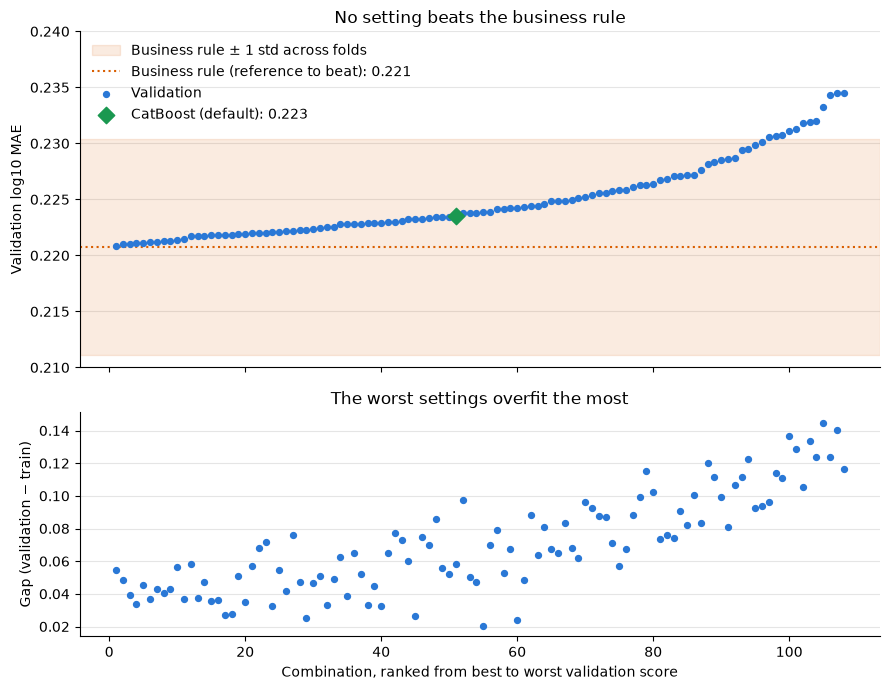

In [44]:
# The 108 combinations ranked from best to worst validation score
ranked = search.sort_values("mean_test_neg_log10_mae", ascending=False)
rank = np.arange(1, len(ranked) + 1)
val_mae = -ranked["mean_test_neg_log10_mae"].to_numpy()
train_mae = -ranked["mean_train_neg_log10_mae"].to_numpy()
gap = val_mae - train_mae

rule_mae = results.loc["Business rule (area x type)", "log10_mae_val_mean"]
rule_std = results.loc["Business rule (area x type)", "log10_mae_val_std"]
default_mae = results.loc["CatBoost (default)", "log10_mae_val_mean"]
default_rank = 1 + (val_mae < default_mae).sum()  # where the default would be ranked

fig, (ax_top, ax_bottom) = plt.subplots(
    2, 1, figsize=(9, 7), sharex=True, gridspec_kw={"height_ratios": [3, 2]}
)

# Top: validation alone, zoomed in
ax_top.axhspan(
    rule_mae - rule_std,
    rule_mae + rule_std,
    color="#d95f02",
    alpha=0.12,
    label="Business rule ± 1 std across folds",
)
ax_top.axhline(
    rule_mae,
    color="#d95f02",
    linestyle=":",
    linewidth=1.5,
    label=f"Business rule (reference to beat): {rule_mae:.3f}",
)
ax_top.scatter(rank, val_mae, s=18, color="#2a78d6", label="Validation", zorder=3)
ax_top.scatter(
    default_rank,
    default_mae,
    s=70,
    marker="D",
    color="#1a9850",
    label=f"CatBoost (default): {default_mae:.3f}",
    zorder=4,
)
ax_top.set_ylim(0.21, max(0.24, val_mae.max() + 0.003))
ax_top.set_ylabel("Validation log10 MAE")
ax_top.set_title("No setting beats the business rule")
ax_top.legend(frameon=False, loc="upper left")

# Bottom: overfitting gap
ax_bottom.scatter(rank, gap, s=18, color="#2a78d6")
ax_bottom.set_ylabel("Gap (validation − train)")
ax_bottom.set_xlabel("Combination, ranked from best to worst validation score")
ax_bottom.set_title("The worst settings overfit the most")

for ax in (ax_top, ax_bottom):
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e5e5e5")
    ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

### Reading the search

- **Tuning reduces the overfitting, but barely improves the error.** The tuned CatBoost is only marginally better than the default one, within the variation across folds. The gap goes from 0.082 to 0.055, it overfits less and is faster to fit.
- **Many settings give the same result.** The best settings are at the edges of the grid for all four hyperparameters, but combinations in the center of the grid yield the same error: there is no trend to extend. The one retained for the final evaluation is not clearly better than the others. A larger grid would likely give the same error and is not worth the fitting time. In the chart, the shaded band is the business rule ± one standard deviation across folds: almost all the 108 combinations fall inside it, so their differences with the rule, and with each other, are within the noise of the cross-validation. The default setting ranks around the middle of the grid, only about 0.002 behind the best one.
- **The tuned CatBoost matches the business rule, but does not beat it.** The two have the same error, and the rule even places slightly more buildings within ±25% of their actual energy use. Ridge is as good as both.
- **In kBtu, the tuned model is not better than the others.** The R² of all the models are within the variation across folds; the rule has the highest one.

**Conclusion.** Tuning makes CatBoost more stable, but it does not make it better than a simple rule based on the area and the type of the buildings. This confirms the reading of section 5: the limit comes from the information in the data, not from the model. The success criterion is not met, so no model is declared the winner at this stage.

Three candidates go to the final evaluation: the business rule, Ridge and the tuned CatBoost. Section 7 compares these three on the test set, not only CatBoost against the rule, because on the cross-validation scores they cannot be told apart. The tuned CatBoost is kept because it overfits less than the default one and it provides feature importances (section 8). The combination was selected on the cross-validation scores, which are slightly optimistic: the test set gives the unbiased value.

## 7. Final evaluation on the test set

_To do._

## 8. Feature importance

_To do._